<a href="https://colab.research.google.com/github/Huy03022005/colb/blob/main/Copy_of_Demo_KTHP_BDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo pandas matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [ ]:
# Tải dữ liệu từ UCI
data = fetch_ucirepo(id=468)

# Lấy dữ liệu đầu vào
X = data.data.features

# Lấy nhãn dự đoán
y = data.data.targets

# Ghép thành một bảng dữ liệu
df = pd.concat([X, y], axis=1)

# Hiển thị 5 dòng đầu tiên
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
# Kiểm tra kích thước dữ liệu
print("Kích thước dữ liệu:", df.shape)

print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

Kích thước dữ liệu: (12330, 18)
Số dòng: 12330
Số cột: 18


In [ ]:
# Hiển thị tên tất cả các cột
print("Danh sách thuộc tính:")

for col in df.columns:
    print(col)

Danh sách thuộc tính:
Administrative
Administrative_Duration
Informational
Informational_Duration
ProductRelated
ProductRelated_Duration
BounceRates
ExitRates
PageValues
SpecialDay
Month
OperatingSystems
Browser
Region
TrafficType
VisitorType
Weekend
Revenue


In [ ]:
# Hiển thị thông tin tổng quan
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
# Thống kê kiểu dữ liệu từng cột
print(df.dtypes)

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


In [ ]:
# Thống kê các thuộc tính số
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [ ]:
# Thống kê riêng một vài thuộc tính
df[[
    "Administrative",
    "Informational",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]].describe().round(2)

,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
count,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00
mean,2.32,0.50,31.73,1194.75,0.02,0.04,5.89
std,3.32,1.27,44.48,1913.67,0.05,0.05,18.57
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,7.00,184.14,0.00,0.01,0.00
50%,1.00,0.00,18.00,598.94,0.00,0.03,0.00
75%,4.00,0.00,38.00,1464.16,0.02,0.05,0.00
max,27.00,24.00,705.00,63973.52,0.20,0.20,361.76


In [ ]:
# Đếm số giá trị thiếu ở từng cột
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [ ]:
# Tổng số ô dữ liệu bị thiếu
print("Tổng giá trị thiếu:", df.isnull().sum().sum())

Tổng giá trị thiếu: 0


In [ ]:
# Đếm số dòng trùng lặp
so_dong_trung = df.duplicated().sum()

print("Số dòng trùng lặp:", so_dong_trung)

Số dòng trùng lặp: 125


In [ ]:
# Hiển thị các dòng có nội dung giống nhau
df[df.duplicated(keep=False)].head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [ ]:
# Đếm số lượng từng lớp
print(df["Revenue"].value_counts())

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [ ]:
# Tính tỷ lệ phần trăm mỗi lớp
ty_le = df["Revenue"].value_counts(normalize=True) * 100

print(ty_le.round(2))

Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


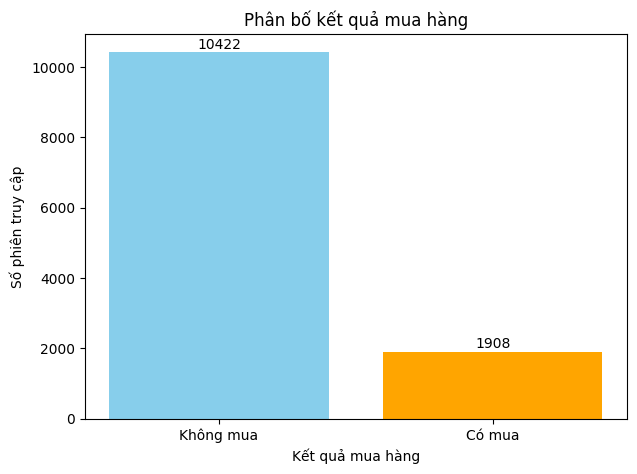

In [ ]:
# Đếm số phiên
dem = df["Revenue"].value_counts()

# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

plt.bar(
    ["Không mua", "Có mua"],
    [dem[False], dem[True]],
    color=["skyblue", "orange"]
)

plt.title("Phân bố kết quả mua hàng")
plt.xlabel("Kết quả mua hàng")
plt.ylabel("Số phiên truy cập")

# Hiển thị số lượng trên cột
for i, value in enumerate([dem[False], dem[True]]):
    plt.text(i, value + 100, str(value), ha="center")

plt.show()

#TIỀN XỬ LÝ VÀ TẠO ĐẶC TRƯNG

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sao chép dữ liệu sau EDA
df_clean = df.copy()

print("Kích thước dữ liệu:", df_clean.shape)
print("Các kiểu dữ liệu:")
display(df_clean.dtypes.to_frame("Kieu_du_lieu"))

print("5 dòng đầu tiên:")
display(df_clean.head())


Kích thước dữ liệu: (12330, 18)
Các kiểu dữ liệu:


,Kieu_du_lieu
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


5 dòng đầu tiên:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



### 2.1.1. Kiểm tra giá trị thiếu (Missing Values)

Giá trị thiếu xuất hiện khi một thuộc tính không được ghi nhận hoặc không có dữ liệu.

**Lý do kiểm tra:**
- Phát hiện các thuộc tính thiếu thông tin.
- Tránh lỗi khi tính toán và huấn luyện mô hình.
- Lựa chọn phương pháp xử lý phù hợp.

**Phương pháp:**
1. Thống kê số lượng và tỷ lệ NaN theo từng cột.
2. Xác định mức độ thiếu dữ liệu.
3. Nếu không có NaN: giữ nguyên dữ liệu.
4. Nếu có NaN: lựa chọn xóa hoặc điền giá trị tùy thuộc vào từng trường hợp.


In [ ]:

# Thống kê NaN theo từng cột
missing_report = pd.DataFrame({
    "So_luong_NaN": df_clean.isna().sum(),
    "Ty_le_%": (df_clean.isna().mean() * 100).round(2)
})

print("BẢNG THỐNG KÊ GIÁ TRỊ THIẾU")
display(missing_report)

total_missing = int(df_clean.isna().sum().sum())

print("Tổng số NaN:", total_missing)
print("Số dòng có ít nhất một NaN:",
      int(df_clean.isna().any(axis=1).sum()))


BẢNG THỐNG KÊ GIÁ TRỊ THIẾU


,So_luong_NaN,Ty_le_%
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Tổng số NaN: 0
Số dòng có ít nhất một NaN: 0


In [ ]:

print("=== ĐÁNH GIÁ GIÁ TRỊ THIẾU ===")

if total_missing == 0:
    print("Kết luận: Không phát hiện NaN.")
    print("Hướng xử lý: Giữ nguyên dữ liệu, không cần điền hoặc xóa.")
else:
    print("Kết luận: Có giá trị thiếu.")
    print("Các cột bị thiếu:")
    display(missing_report[missing_report["So_luong_NaN"] > 0])

    print("Hướng xử lý đề xuất:")
    print("- Cột số: xem xét điền Median.")
    print("- Cột phân loại: xem xét điền Mode.")
    print("- Revenue: kiểm tra riêng vì đây là nhãn dự đoán.")
    print("- Không xóa toàn bộ dòng thiếu một cách tự động.")

print("Lưu ý: Nếu cần điền NaN, phải fit bộ điền giá trị trên Train.")


=== ĐÁNH GIÁ GIÁ TRỊ THIẾU ===
Kết luận: Không phát hiện NaN.
Hướng xử lý: Giữ nguyên dữ liệu, không cần điền hoặc xóa.
Lưu ý: Nếu cần điền NaN, phải fit bộ điền giá trị trên Train.



### 2.1.2. Kiểm tra dữ liệu trùng lặp (Duplicate Data)

Dữ liệu trùng lặp là các dòng có cùng giá trị ở toàn bộ thuộc tính được so sánh.

**Lý do kiểm tra:**
- Phát hiện khả năng dữ liệu bị ghi nhận hoặc sao chép nhiều lần.
- Tránh việc dữ liệu lỗi làm sai lệch phân tích.

**Lưu ý đối với bộ dữ liệu:**
Một dòng biểu diễn một phiên truy cập. Hai phiên độc lập có thể có đặc trưng giống nhau.

Vì vậy, phát hiện trùng lặp không đồng nghĩa với việc phải xóa.


In [ ]:

duplicate_count = int(df_clean.duplicated().sum())
duplicate_rate = duplicate_count / len(df_clean) * 100

print("=== THỐNG KÊ TRÙNG LẶP ===")
print("Tổng số dòng:", len(df_clean))
print("Số dòng trùng:", duplicate_count)
print(f"Tỷ lệ dòng trùng: {duplicate_rate:.2f}%")

print("\nVí dụ các dòng trùng (nếu có):")

duplicate_rows = df_clean[
    df_clean.duplicated(keep=False)
]

display(duplicate_rows.head(10))


=== THỐNG KÊ TRÙNG LẶP ===
Tổng số dòng: 12330
Số dòng trùng: 125
Tỷ lệ dòng trùng: 1.01%

Ví dụ các dòng trùng (nếu có):


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [ ]:

print("=== ĐÁNH GIÁ TRÙNG LẶP ===")

if duplicate_count == 0:
    print("Không phát hiện dòng trùng.")
    print("Hướng xử lý: Giữ nguyên dữ liệu.")
else:
    print(f"Phát hiện {duplicate_count} dòng trùng.")
    print("Chưa đủ căn cứ để kết luận đây là lỗi.")
    print("Hướng xử lý: Tạm giữ nguyên các dòng.")
    print("Chỉ xóa nếu xác minh được đây là bản ghi bị sao chép.")

# Không tự động sử dụng drop_duplicates()
print("\nSố dòng sau bước kiểm tra:", len(df_clean))


=== ĐÁNH GIÁ TRÙNG LẶP ===
Phát hiện 125 dòng trùng.
Chưa đủ căn cứ để kết luận đây là lỗi.
Hướng xử lý: Tạm giữ nguyên các dòng.
Chỉ xóa nếu xác minh được đây là bản ghi bị sao chép.

Số dòng sau bước kiểm tra: 12330



### 2.1.3. Kiểm tra giá trị không hợp lệ và dữ liệu nhiễu

Dữ liệu không hợp lệ là dữ liệu vi phạm các quy tắc về ý nghĩa hoặc miền giá trị.

**Các quy tắc kiểm tra:**
- Số lượt xem trang không được âm.
- Thời gian duyệt trang không được âm.
- BounceRates, ExitRates và SpecialDay phải trong khoảng [0, 1].
- Các biến số đếm phải có giá trị nguyên không âm.

**Phương pháp xử lý:**
- Nếu giá trị hợp lệ: giữ nguyên.
- Nếu phát hiện giá trị sai: kiểm tra bản ghi và nguyên nhân.
- Không tự động xóa giá trị lớn hoặc giá trị bằng 0.


In [ ]:

non_negative_cols = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "PageValues"
]

rate_cols = [
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

count_cols = [
    "Administrative",
    "Informational",
    "ProductRelated"
]

invalid_results = []

for col in non_negative_cols:
    invalid_results.append({
        "Cot": col,
        "Loai_vi_pham": "Gia tri am",
        "So_luong": int((df_clean[col] < 0).sum())
    })

for col in rate_cols:
    mask = (
        (df_clean[col] < 0) |
        (df_clean[col] > 1)
    )
    invalid_results.append({
        "Cot": col,
        "Loai_vi_pham": "Ngoai [0,1]",
        "So_luong": int(mask.sum())
    })

for col in count_cols:
    mask = (
        df_clean[col].notna() &
        (df_clean[col] % 1 != 0)
    )
    invalid_results.append({
        "Cot": col,
        "Loai_vi_pham": "So dem khong nguyen",
        "So_luong": int(mask.sum())
    })

invalid_report = pd.DataFrame(invalid_results)

display(invalid_report)

total_invalid = int(invalid_report["So_luong"].sum())

print("Tổng lượt vi phạm:", total_invalid)


,Cot,Loai_vi_pham,So_luong
0,Administrative,Gia tri am,0
1,Informational,Gia tri am,0
2,ProductRelated,Gia tri am,0
3,Administrative_Duration,Gia tri am,0
4,Informational_Duration,Gia tri am,0
5,ProductRelated_Duration,Gia tri am,0
6,PageValues,Gia tri am,0
7,BounceRates,"Ngoai [0,1]",0
8,ExitRates,"Ngoai [0,1]",0
9,SpecialDay,"Ngoai [0,1]",0


Tổng lượt vi phạm: 0


In [ ]:

print("=== ĐÁNH GIÁ GIÁ TRỊ KHÔNG HỢP LỆ ===")

if total_invalid == 0:
    print("Không phát hiện vi phạm trong các quy tắc đã kiểm tra.")
    print("Hướng xử lý: Giữ nguyên dữ liệu.")
else:
    print("Phát hiện giá trị vi phạm quy tắc.")
    print("Cần kiểm tra các bản ghi liên quan.")

    display(
        invalid_report[invalid_report["So_luong"] > 0]
    )

    print("Chưa tự động sửa hoặc xóa dữ liệu.")

print("\nSố dòng hiện tại:", len(df_clean))


=== ĐÁNH GIÁ GIÁ TRỊ KHÔNG HỢP LỆ ===
Không phát hiện vi phạm trong các quy tắc đã kiểm tra.
Hướng xử lý: Giữ nguyên dữ liệu.

Số dòng hiện tại: 12330



### 2.1.4. Phân tích giá trị ngoại lệ (Outliers)

Ngoại lệ là những giá trị khác biệt lớn so với phần lớn dữ liệu.

Ví dụ: một phiên truy cập có thời gian xem trang sản phẩm rất cao.

**Mục đích:**
- Hiểu phân bố của các thuộc tính thời gian.
- Phát hiện những phiên có hành vi khác biệt.
- Đánh giá có cần biến đổi hoặc xử lý ngoại lệ hay không.

**Phương pháp:**
- Boxplot để quan sát ngoại lệ.
- Histogram để xem hình dạng phân bố.
- IQR để thống kê số giá trị nằm ngoài ngưỡng.

Không tự động xóa ngoại lệ vì chúng có thể phản ánh hành vi thực tế.


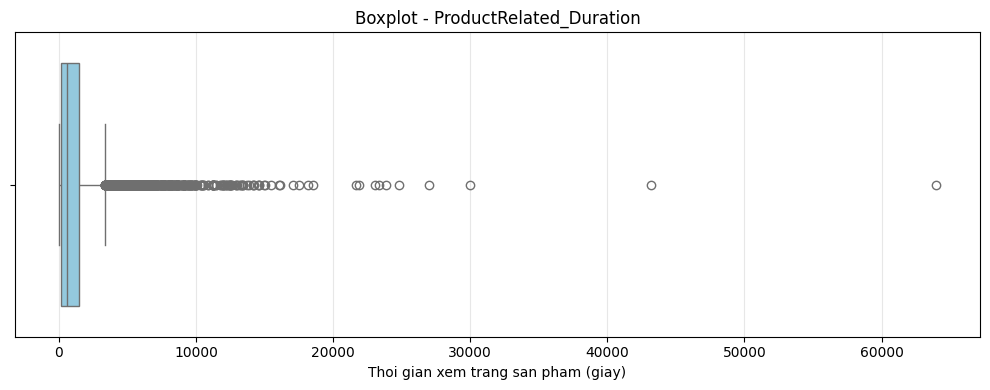

In [ ]:

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df_clean["ProductRelated_Duration"],
    color="skyblue"
)

plt.title("Boxplot - ProductRelated_Duration")
plt.xlabel("Thoi gian xem trang san pham (giay)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


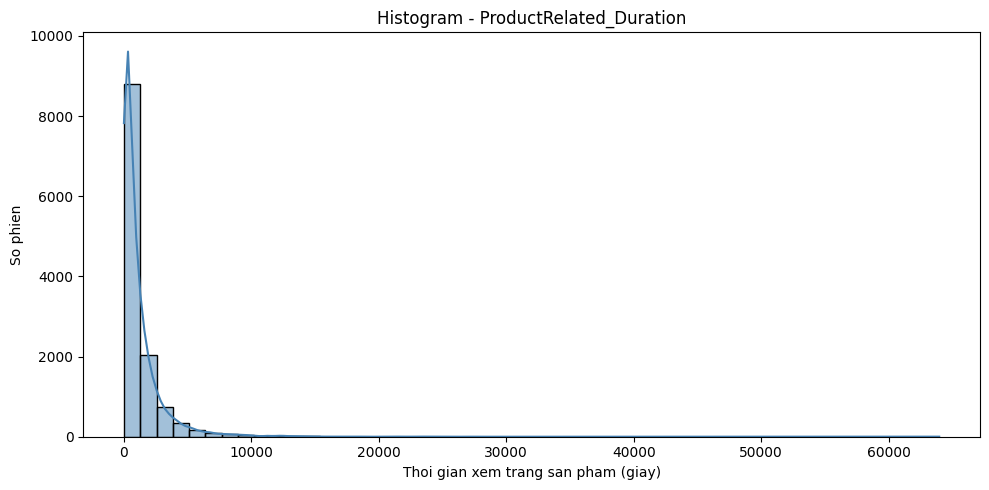

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["ProductRelated_Duration"].dropna(),
    bins=50,
    kde=True,
    color="steelblue"
)

plt.title("Histogram - ProductRelated_Duration")
plt.xlabel("Thoi gian xem trang san pham (giay)")
plt.ylabel("So phien")

plt.tight_layout()
plt.show()


In [ ]:

outlier_cols = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "PageValues"
]

outlier_results = []

for col in outlier_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    )

    outlier_results.append({
        "Cot": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Nguong_duoi": lower,
        "Nguong_tren": upper,
        "So_ngoai_le": int(mask.sum()),
        "Ty_le_%": round(mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(2))


,Cot,Q1,Q3,IQR,Nguong_duoi,Nguong_tren,So_ngoai_le,Ty_le_%
0,Administrative_Duration,0.00,93.26,93.26,-139.88,233.14,1172,9.51
1,Informational_Duration,0.00,0.00,0.00,0.00,0.00,2405,19.51
2,ProductRelated_Duration,184.14,1464.16,1280.02,-1735.89,3384.19,961,7.79
3,PageValues,0.00,0.00,0.00,0.00,0.00,2730,22.14


In [ ]:

print("=== ĐÁNH GIÁ NGOẠI LỆ ===")

display(
    outlier_report[[
        "Cot", "So_ngoai_le", "Ty_le_%"
    ]]
)

print("\nPhương án xử lý đề xuất:")
print("1. Giữ các ngoại lệ chưa xác định là lỗi.")
print("2. Không tự động xóa theo ngưỡng IQR.")
print("3. Không thay ngoại lệ bằng giá trị trung bình.")
print("4. Đánh giá ảnh hưởng khi huấn luyện mô hình.")

if total_invalid > 0:
    raise ValueError(
        "Phát hiện giá trị không hợp lệ. "
        "Hãy xem xét và xử lý trước khi mã hóa."
    )

print("\nHoàn thành kiểm tra dữ liệu thô.")


=== ĐÁNH GIÁ NGOẠI LỆ ===


,Cot,So_ngoai_le,Ty_le_%
0,Administrative_Duration,1172,9.51
1,Informational_Duration,2405,19.51
2,ProductRelated_Duration,961,7.79
3,PageValues,2730,22.14



Phương án xử lý đề xuất:
1. Giữ các ngoại lệ chưa xác định là lỗi.
2. Không tự động xóa theo ngưỡng IQR.
3. Không thay ngoại lệ bằng giá trị trung bình.
4. Đánh giá ảnh hưởng khi huấn luyện mô hình.

Hoàn thành kiểm tra dữ liệu thô.



## 2.2. Mã hóa dữ liệu (Encoding)

### 2.2.1. Mã hóa biến Boolean

Hai thuộc tính Boolean trong bộ dữ liệu là:
- Weekend: phiên truy cập diễn ra vào cuối tuần hay không.
- Revenue: phiên truy cập có giao dịch mua hàng hay không.

**Mục đích:**
- Biểu diễn dữ liệu dưới dạng số.
- Thống nhất định dạng cho các bước xử lý tiếp theo.
- Thuận tiện cho việc huấn luyện và đánh giá mô hình.

**Phương pháp:** Chuyển True thành 1, False thành 0.

Lưu ý: Revenue là biến mục tiêu, không được đưa vào tập đặc trưng X.


In [ ]:

print("=== KIỂM TRA BOOLEAN TRƯỚC MÃ HÓA ===")

for col in ["Weekend", "Revenue"]:
    print(f"\nCột: {col}")
    print("Kiểu dữ liệu:", df_clean[col].dtype)
    print("Các giá trị và số lần xuất hiện:")
    display(df_clean[col].value_counts(dropna=False))

display(df_clean[["Weekend", "Revenue"]].head(10))


=== KIỂM TRA BOOLEAN TRƯỚC MÃ HÓA ===

Cột: Weekend
Kiểu dữ liệu: bool
Các giá trị và số lần xuất hiện:


,count
Weekend,
False,9462
True,2868



Cột: Revenue
Kiểu dữ liệu: bool
Các giá trị và số lần xuất hiện:


,count
Revenue,
False,10422
True,1908


,Weekend,Revenue
0,False,False
1,False,False
2,False,False
3,False,False
4,True,False
5,False,False
6,False,False
7,True,False
8,False,False
9,False,False


In [ ]:

def convert_boolean(series):
    mapping = {
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    }

    values = series.astype("string").str.strip().str.lower()
    encoded = values.map(mapping)

    invalid = series.notna() & encoded.isna()

    if invalid.any():
        raise ValueError(
            f"Phát hiện {invalid.sum()} giá trị Boolean không hợp lệ"
        )

    return encoded.astype("Int64")


for col in ["Weekend", "Revenue"]:
    df_clean[col] = convert_boolean(df_clean[col])

print("=== KẾT QUẢ SAU MÃ HÓA ===")
display(df_clean[["Weekend", "Revenue"]].head(10))

print("Kiểu dữ liệu:")
print(df_clean[["Weekend", "Revenue"]].dtypes)

print("Phân bố Revenue:")
display(df_clean["Revenue"].value_counts(dropna=False))


=== KẾT QUẢ SAU MÃ HÓA ===


,Weekend,Revenue
0,0,0
1,0,0
2,0,0
3,0,0
4,1,0
5,0,0
6,0,0
7,1,0
8,0,0
9,0,0


Kiểu dữ liệu:
Weekend    Int64
Revenue    Int64
dtype: object
Phân bố Revenue:


,count
Revenue,
0,10422
1,1908



## 2.3. Tạo đặc trưng mới (Feature Engineering)

Feature Engineering là quá trình xây dựng các thuộc tính mới từ dữ liệu hiện có.

**Lý do thực hiện:**
- Tổng hợp thông tin hành vi đang phân tán ở nhiều cột.
- Biểu diễn rõ hơn mức độ tương tác với website.
- Cung cấp thêm thông tin tiềm năng cho mô hình dự đoán.

**Các đặc trưng:**
1. Total_Duration: tổng thời gian ghi nhận trên các nhóm trang.
2. Total_Pages: tổng lượt xem trang.
3. Product_Page_Ratio: tỷ trọng xem trang sản phẩm.
4. Avg_Product_Duration: thời gian trung bình trên mỗi lượt xem trang sản phẩm.

Các đặc trưng mới chỉ sử dụng thông tin trong chính phiên truy cập, không sử dụng Revenue.


In [ ]:

# Tổng thời gian duyệt các nhóm trang
df_clean["Total_Duration"] = (
    df_clean["Administrative_Duration"]
    + df_clean["Informational_Duration"]
    + df_clean["ProductRelated_Duration"]
)

# Tổng số lượt xem trang
df_clean["Total_Pages"] = (
    df_clean["Administrative"]
    + df_clean["Informational"]
    + df_clean["ProductRelated"]
)

print("=== TỔNG THỜI GIAN VÀ SỐ TRANG ===")

display(df_clean[[
    "Administrative",
    "Informational",
    "ProductRelated",
    "Total_Pages",
    "Total_Duration"
]].head(10))


=== TỔNG THỜI GIAN VÀ SỐ TRANG ===


,Administrative,Informational,ProductRelated,Total_Pages,Total_Duration
0,0,0,1,1,0.000000
1,0,0,2,2,64.000000
2,0,0,1,1,0.000000
3,0,0,2,2,2.666667
4,0,0,10,10,627.500000
5,0,0,19,19,154.216667
6,0,0,1,1,0.000000
7,1,0,0,1,0.000000
8,0,0,2,2,37.000000
9,0,0,3,3,738.000000


In [ ]:

# Tổng thời gian duyệt các nhóm trang
df_clean["Total_Duration"] = (
    df_clean["Administrative_Duration"]
    + df_clean["Informational_Duration"]
    + df_clean["ProductRelated_Duration"]
)

# Tổng số lượt xem trang
df_clean["Total_Pages"] = (
    df_clean["Administrative"]
    + df_clean["Informational"]
    + df_clean["ProductRelated"]
)

print("=== TỔNG THỜI GIAN VÀ SỐ TRANG ===")

display(df_clean[[
    "Administrative",
    "Informational",
    "ProductRelated",
    "Total_Pages",
    "Total_Duration"
]].head(10))


=== TỔNG THỜI GIAN VÀ SỐ TRANG ===


,Administrative,Informational,ProductRelated,Total_Pages,Total_Duration
0,0,0,1,1,0.000000
1,0,0,2,2,64.000000
2,0,0,1,1,0.000000
3,0,0,2,2,2.666667
4,0,0,10,10,627.500000
5,0,0,19,19,154.216667
6,0,0,1,1,0.000000
7,1,0,0,1,0.000000
8,0,0,2,2,37.000000
9,0,0,3,3,738.000000


In [ ]:

# Tỷ trọng xem trang sản phẩm
df_clean["Product_Page_Ratio"] = (
    df_clean["ProductRelated"]
    / df_clean["Total_Pages"].replace(0, np.nan)
).fillna(0)

# Thời gian trung bình trên mỗi trang sản phẩm
df_clean["Avg_Product_Duration"] = (
    df_clean["ProductRelated_Duration"]
    / df_clean["ProductRelated"].replace(0, np.nan)
).fillna(0)

print("=== ĐẶC TRƯNG TỶ LỆ ===")

display(df_clean[[
    "ProductRelated",
    "Total_Pages",
    "Product_Page_Ratio",
    "ProductRelated_Duration",
    "Avg_Product_Duration"
]].head(10))


=== ĐẶC TRƯNG TỶ LỆ ===


,ProductRelated,Total_Pages,Product_Page_Ratio,ProductRelated_Duration,Avg_Product_Duration
0,1,1,1.0,0.000000,0.000000
1,2,2,1.0,64.000000,32.000000
2,1,1,1.0,0.000000,0.000000
3,2,2,1.0,2.666667,1.333333
4,10,10,1.0,627.500000,62.750000
5,19,19,1.0,154.216667,8.116667
6,1,1,1.0,0.000000,0.000000
7,0,1,0.0,0.000000,0.000000
8,2,2,1.0,37.000000,18.500000
9,3,3,1.0,738.000000,246.000000


In [ ]:

new_features = [
    "Total_Duration",
    "Total_Pages",
    "Product_Page_Ratio",
    "Avg_Product_Duration"
]

print("=== THỐNG KÊ ĐẶC TRƯNG MỚI ===")

display(df_clean[new_features].describe().round(2))

print("Số NaN theo đặc trưng:")
display(df_clean[new_features].isna().sum())

ratio_invalid = (
    (df_clean["Product_Page_Ratio"] < 0) |
    (df_clean["Product_Page_Ratio"] > 1)
)

print("Số tỷ trọng ngoài [0,1]:", ratio_invalid.sum())

print("Số Total_Pages bằng 0:",
      (df_clean["Total_Pages"] == 0).sum())

print("Số ProductRelated bằng 0:",
      (df_clean["ProductRelated"] == 0).sum())


=== THỐNG KÊ ĐẶC TRƯNG MỚI ===


,Total_Duration,Total_Pages,Product_Page_Ratio,Avg_Product_Duration
count,12330.00,12330.00,12330.00,12330.00
mean,1310.04,34.55,0.91,37.63
std,2037.80,46.51,0.14,44.77
min,0.00,0.00,0.00,0.00
25%,222.00,8.00,0.86,17.61
50%,680.00,20.00,0.96,28.88
75%,1626.91,42.00,1.00,45.08
max,69921.65,746.00,1.00,1411.00


Số NaN theo đặc trưng:


,0
Total_Duration,0
Total_Pages,0
Product_Page_Ratio,0
Avg_Product_Duration,0


Số tỷ trọng ngoài [0,1]: 0
Số Total_Pages bằng 0: 6
Số ProductRelated bằng 0: 38


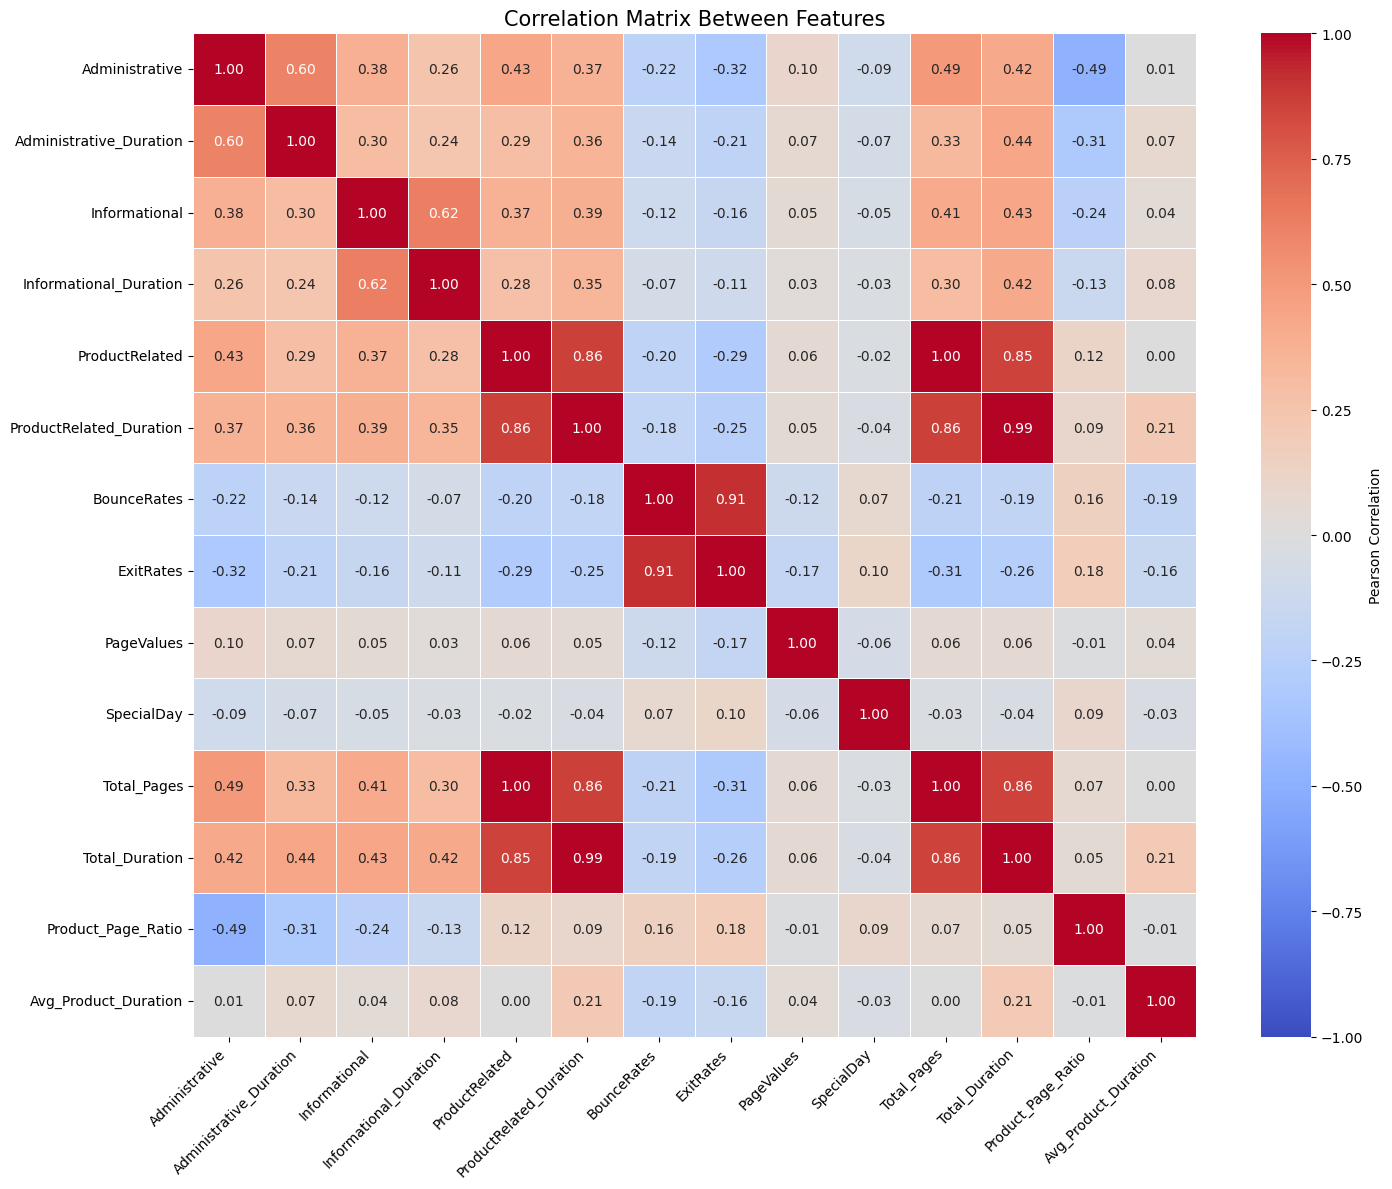

In [ ]:
features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Total_Pages",
    "Total_Duration",
    "Product_Page_Ratio",
    "Avg_Product_Duration"
]

# Tính ma trận tương quan Pearson
corr_matrix = df_clean[features].corr(method="pearson")

# Vẽ ma trận tương quan dạng ô vuông
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    annot=True,           # Hiển thị hệ số trong từng ô
    fmt=".2f",            # Làm tròn 2 chữ số
    cmap="coolwarm",      # Màu xanh - trắng - đỏ
    vmin=-1,
    vmax=1,
    center=0,
    square=True,          # Các ô hình vuông
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Matrix Between Features", fontsize=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



## 2.4. Chuẩn bị dữ liệu để mã hóa và chuẩn hóa

Trước khi fit các bộ biến đổi dựa trên dữ liệu, cần chia tập Train và Test.

**Lý do:**
- Tránh sử dụng thông tin thống kê của Test khi xử lý Train.
- Giữ cho tập kiểm thử độc lập.
- Đảm bảo cùng một bộ biến đổi được áp dụng nhất quán.

**Phương pháp:**
- 80% dữ liệu cho Train.
- 20% dữ liệu cho Test.
- Dùng stratify theo Revenue để giữ tỷ lệ hai lớp.

Tỷ lệ 80/20 là lựa chọn thử nghiệm và cần thống nhất với người thực hiện Phần 3.


In [ ]:

from sklearn.model_selection import train_test_split

if df_clean["Revenue"].isna().any():
    raise ValueError("Revenue còn giá trị thiếu!")

X = df_clean.drop(columns=["Revenue"])
y = df_clean["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("=== KÍCH THƯỚC TRAIN / TEST ===")
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nTỷ lệ Revenue toàn bộ dữ liệu:")
display(y.value_counts(normalize=True).round(4))

print("\nTỷ lệ Revenue trong Train:")
display(y_train.value_counts(normalize=True).round(4))

print("\nTỷ lệ Revenue trong Test:")
display(y_test.value_counts(normalize=True).round(4))


=== KÍCH THƯỚC TRAIN / TEST ===
Train: (9864, 21)
Test: (2466, 21)

Tỷ lệ Revenue toàn bộ dữ liệu:


,proportion
Revenue,
0,0.8453
1,0.1547



Tỷ lệ Revenue trong Train:


,proportion
Revenue,
0,0.8453
1,0.1547



Tỷ lệ Revenue trong Test:


,proportion
Revenue,
0,0.8451
1,0.1549



### 2.4.1. One-Hot Encoding

Các cột Month và VisitorType là biến phân loại.

Ngoài ra, OperatingSystems, Browser, Region và TrafficType tuy được biểu diễn bằng số nhưng thực chất là mã danh mục.

**Phương pháp:** One-Hot Encoding.

Mỗi danh mục được chuyển thành một cột nhị phân.

**Lưu ý:**
- Chỉ fit OneHotEncoder trên Train.
- Sử dụng Encoder đó cho Test.
- Không mã hóa Revenue như một đặc trưng đầu vào.


In [ ]:

categorical_cols = [
    "Month",
    "VisitorType",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

print("=== CÁC CỘT PHÂN LOẠI ===")

for col in categorical_cols:
    print(f"{col}: {X_train[col].nunique()} nhóm")
    display(X_train[col].value_counts().head(10))

print("Ví dụ dữ liệu trước mã hóa:")
display(X_train[categorical_cols].head())


=== CÁC CỘT PHÂN LOẠI ===
Month: 10 nhóm


,count
Month,
May,2703
Nov,2360
Mar,1538
Dec,1391
Oct,444
Sep,368
Jul,344
Aug,342
June,228


VisitorType: 3 nhóm


,count
VisitorType,
Returning_Visitor,8443
New_Visitor,1347
Other,74


OperatingSystems: 8 nhóm


,count
OperatingSystems,
2,5275
1,2063
3,2050
4,383
8,67
6,17
5,5
7,4


... (4 outputs left out)

TrafficType: 20 nhóm


,count
TrafficType,
2,3135
1,1934
3,1654
4,866
13,581
10,370
6,350
8,268
5,215


Ví dụ dữ liệu trước mã hóa:


,Month,VisitorType,OperatingSystems,Browser,Region,TrafficType
4263,May,Returning_Visitor,3,3,3,2
5905,Oct,Returning_Visitor,1,8,3,1
9434,Dec,Returning_Visitor,2,10,1,2
3505,May,Returning_Visitor,3,2,2,2
2067,Mar,Returning_Visitor,2,2,7,2


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

# Scaling là tùy chọn
USE_SCALING = False

numeric_steps = [
    ("imputer", SimpleImputer(strategy="median"))
]

if USE_SCALING:
    numeric_steps.append(
        ("scaler", StandardScaler())
    )

numeric_pipeline = Pipeline(numeric_steps)

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Chỉ fit trên Train
X_train_array = preprocessor.fit_transform(X_train)

# Test chỉ transform, không fit lại
X_test_array = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_array,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_array,
    columns=feature_names,
    index=X_test.index
)

print("=== KẾT QUẢ MÃ HÓA ===")
print("Train trước:", X_train.shape)
print("Train sau:", X_train_processed.shape)
print("Test trước:", X_test.shape)
print("Test sau:", X_test_processed.shape)


=== KẾT QUẢ MÃ HÓA ===
Train trước: (9864, 21)
Train sau: (9864, 78)
Test trước: (2466, 21)
Test sau: (2466, 78)


In [ ]:

print("=== TRƯỚC ONE-HOT ===")
display(X_train[["Month", "VisitorType"]].head(10))

onehot_cols = [
    col for col in X_train_processed.columns
    if col.startswith("cat__Month_")
    or col.startswith("cat__VisitorType_")
]

print("=== SAU ONE-HOT ===")
display(X_train_processed[onehot_cols].head(10))


=== TRƯỚC ONE-HOT ===


,Month,VisitorType
4263,May,Returning_Visitor
5905,Oct,Returning_Visitor
9434,Dec,Returning_Visitor
3505,May,Returning_Visitor
2067,Mar,Returning_Visitor
10113,Nov,Returning_Visitor
9335,Nov,New_Visitor
1868,Mar,New_Visitor
4322,May,New_Visitor
265,Mar,Returning_Visitor


=== SAU ONE-HOT ===


,cat__Month_Aug,cat__Month_Dec,cat__Month_Feb,cat__Month_Jul,cat__Month_June,cat__Month_Mar,cat__Month_May,cat__Month_Nov,cat__Month_Oct,cat__Month_Sep,cat__VisitorType_New_Visitor,cat__VisitorType_Other,cat__VisitorType_Returning_Visitor
4263,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5905,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
9434,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3505,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2067,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10113,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
9335,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1868,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4322,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
265,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:

print("=== PHƯƠNG PHÁP SCALING ===")

if USE_SCALING:
    print("Đã áp dụng StandardScaler cho biến số.")
    print("Scaler được fit trên Train.")
else:
    print("Không áp dụng Scaling.")
    print("Lý do: sử dụng mô hình dựa trên cây.")
    print("Giữ nguyên thang đo các đặc trưng số.")


=== PHƯƠNG PHÁP SCALING ===
Không áp dụng Scaling.
Lý do: sử dụng mô hình dựa trên cây.
Giữ nguyên thang đo các đặc trưng số.


In [ ]:

print("=== KIỂM TRA DỮ LIỆU SAU TIỀN XỬ LÝ ===")

print("Train:", X_train_processed.shape)
print("Test:", X_test_processed.shape)

print("NaN trong Train:",
      X_train_processed.isna().sum().sum())

print("NaN trong Test:",
      X_test_processed.isna().sum().sum())

print("Kiểu dữ liệu:")
display(X_train_processed.dtypes.value_counts())

assert X_train_processed.columns.equals(
    X_test_processed.columns
), "Train và Test không cùng cấu trúc!"

assert X_train_processed.isna().sum().sum() == 0
assert X_test_processed.isna().sum().sum() == 0

assert np.isfinite(X_train_processed.to_numpy()).all()
assert np.isfinite(X_test_processed.to_numpy()).all()

assert "Revenue" not in X_train_processed.columns

print("\nHOÀN THÀNH TIỀN XỬ LÝ DỮ LIỆU!")


=== KIỂM TRA DỮ LIỆU SAU TIỀN XỬ LÝ ===
Train: (9864, 78)
Test: (2466, 78)
NaN trong Train: 0
NaN trong Test: 0
Kiểu dữ liệu:


,count
float64,78



HOÀN THÀNH TIỀN XỬ LÝ DỮ LIỆU!


In [ ]:

summary = pd.DataFrame({
    "Noi_dung": [
        "Số dòng dữ liệu ban đầu",
        "Số cột ban đầu",
        "Tổng NaN phát hiện",
        "Số dòng trùng phát hiện",
        "Tổng lượt vi phạm quy tắc",
        "Số đặc trưng được tạo mới",
        "Số dòng Train",
        "Số dòng Test",
        "Số cột Train sau mã hóa",
        "Số cột Test sau mã hóa",
        "NaN còn lại trong Train",
        "NaN còn lại trong Test",
        "Có áp dụng Scaling"
    ],
    "Ket_qua": [
        df.shape[0],
        df.shape[1],
        total_missing,
        duplicate_count,
        total_invalid,
        len(new_features),
        X_train_processed.shape[0],
        X_test_processed.shape[0],
        X_train_processed.shape[1],
        X_test_processed.shape[1],
        int(X_train_processed.isna().sum().sum()),
        int(X_test_processed.isna().sum().sum()),
        USE_SCALING
    ]
})

display(summary)


,Noi_dung,Ket_qua
0,Số dòng dữ liệu ban đầu,12330
1,Số cột ban đầu,18
2,Tổng NaN phát hiện,0
3,Số dòng trùng phát hiện,125
4,Tổng lượt vi phạm quy tắc,0
5,Số đặc trưng được tạo mới,4
6,Số dòng Train,9864
7,Số dòng Test,2466
8,Số cột Train sau mã hóa,78
9,Số cột Test sau mã hóa,78


```markdown
# PHẦN 4: THIẾT LẬP MÔI TRƯỜNG VÀ CẤU HÌNH BENCHMARK (SCALED x100)

Trong phần này, chúng ta tiến hành chuẩn bị các thành phần cần thiết để đo đạc và đối chiếu hiệu năng một cách công bằng giữa hai hệ sinh thái:
1. **Đơn máy (Single-node):** Sử dụng thư viện truyền thống **scikit-learn** kết hợp với **Pandas** để xử lý dữ liệu trực tiếp trong bộ nhớ RAM vật lý của Python.
2. **Phân tán (Distributed):** Sử dụng **PySpark** và thư viện **Spark MLlib** hoạt động trên nền tảng Java Virtual Machine (JVM).

### Các bước chuẩn bị:
- Kiểm tra số lượng vCPUs thực tế của hệ thống máy chủ Google Colab để ánh xạ trực tiếp số lõi tính toán song song (`CORES`).
- Thiết lập danh sách hệ số nhân bản dữ liệu (`SCALES = [1, 10, 20, 50, 100]`), trong đó quy mô cực đại `x100` sẽ tạo ra tập dữ liệu gần **1 triệu dòng** huấn luyện.
- Tải gói cài đặt JDK 17 (Java Development Kit) và thư viện PySpark để khởi tạo cơ sở hạ tầng cho Spark.
```

### 4. Đánh giá chi tiết hiệu năng & Đề xuất quy mô x100

#### 1. Đánh giá tính tối ưu của Spark trong bài test hiện tại:
- **Chi phí khởi động (Startup overhead):** Spark mất từ **15s đến 36s** chỉ để khởi tạo `SparkSession` và JVM. Với tập dữ liệu nhỏ (`x1` - 9,864 dòng), chi phí này chiếm phần lớn tổng thời gian thực hiện, làm Spark chậm hơn scikit-learn rất nhiều.
- **Tốc độ xử lý (Pipeline Runtime):**
  - Khi tăng quy mô lên `x50` (493,200 dòng), thời gian chạy của **scikit-learn** tăng từ `1.25s` lên `30.31s` (tăng gấp **24 lần**).
  - Ngược lại, **Spark** tăng thời gian chạy từ `51.2s` lên `140.25s` (chỉ tăng **2.7 lần**).
- **Mức độ tiêu thụ bộ nhớ (Peak Memory):** Spark tiêu thụ bộ nhớ lớn hơn lúc đầu nhưng duy trì mức tăng rất chậm và ổn định nhờ cấu trúc phân vùng dữ liệu thông minh, tránh hiện tượng nghẽn cổ chai RAM cục bộ.

#### 2. Kết luận & Đề xuất thực hiện scale x100 (~1 triệu dòng):
- **Spark đã tối ưu chưa?** Spark đã được cấu hình tối ưu phân mảnh (`spark.sql.shuffle.partitions` và `spark.default.parallelism` tương ứng với số Cores thực tế) và tận dụng lưu trữ đệm `MEMORY_AND_DISK`. Tuy nhiên, sức mạnh xử lý song song chỉ thực sự phát huy khi kích thước dữ liệu đủ lớn để bù đắp chi phí khởi tạo JVM.
- **Có cần nhân lên x100 không?** **Có**. Ở mức `x100` (~1,000,000 dòng train), scikit-learn sẽ tốn rất nhiều bộ nhớ trên một tiến trình đơn lẻ và có nguy cơ quá tải tài nguyên (OOM), đây sẽ là ngưỡng phân cực rõ rệt nhất cho thấy ưu thế của mô hình phân tán Spark.

In [ ]:
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark pyarrow psutil ucimlrepo
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
!java -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


```markdown
### Thiết lập tệp thực thi Worker tách biệt (`pipeline_worker.py`)

Để đo lường dung lượng RAM tiêu thụ đỉnh điểm (**Peak Memory**) của mỗi hệ thống một cách chuẩn xác mà không bị ảnh hưởng bởi bộ nhớ đệm của Google Colab Notebook, chúng ta xây dựng cấu trúc **Worker Process** độc lập:
- Đo lường Peak Memory theo thời gian thực (lấy mẫu mỗi 50ms) bằng thư viện `psutil` nhằm ghi nhận cả RAM hệ thống của JVM và tiến trình con.
- Đảm bảo các mô hình phân loại Random Forest trên cả hai nền tảng sử dụng chung các siêu tham số nghiêm ngặt:
  - Số cây quyết định (`n_estimators`/`numTrees`) = **50 cây**.
  - Độ sâu tối đa của cây (`maxDepth`) = **10**.
  - Tiêu chí lựa chọn đặc trưng tại mỗi nhánh quyết định = `sqrt` (căn bậc hai tổng số thuộc tính).
```

```markdown
### Chi tiết cấu trúc mã nguồn thực thi độc lập (`pipeline_worker.py`)

Đoạn mã dưới đây được ghi trực tiếp thành một tệp tin Python chạy độc lập. Việc chạy độc lập này giúp cô lập hoàn toàn tài nguyên CPU và bộ nhớ giữa các lần thử nghiệm.

#### 1. Lớp giám sát bộ nhớ `PeakMemory`
- Khởi chạy một luồng phụ chạy ngầm (`threading.Thread`) liên tục lấy mẫu dữ liệu mỗi `50ms`.
- Sử dụng thư viện `psutil` để quét qua tiến trình chính và mọi tiến trình con (bao gồm cả tiến trình Java Virtual Machine của Spark) để tính toán chính xác tổng lượng RAM vật lý thực tế tiêu thụ (`RSS`).

#### 2. Nhánh xử lý Đơn Máy (`run_sklearn`)
- Sử dụng **Pandas** để nạp và nhân bản dữ liệu trên bộ nhớ trong.
- Tiền xử lý dữ liệu và mã hóa Boolean.
- Sử dụng **Scikit-learn** `ColumnTransformer` để tự động điền khuyết giá trị và mã hóa One-Hot.
- Huấn luyện mô hình `RandomForestClassifier` song song hóa đa lõi bằng CPU thông qua luồng quản lý gốc (`n_jobs=cores`).

#### 3. Nhánh xử lý Phân Tán (`run_spark`)
- Khởi chạy môi trường **SparkSession** cục bộ với các tham số tối ưu hóa luồng và bộ đệm.
- Nhân bản dữ liệu trực tiếp bằng truy vấn phân tán (`crossJoin`) kết hợp cơ chế chia phân mảnh dữ liệu chủ động (`repartition`).
- Thiết lập Pipeline xử lý biến đổi đặc trưng qua các thực thể `Imputer`, `StringIndexer` và `OneHotEncoder` tích hợp sẵn trong thư viện Spark MLlib.
- Huấn luyện mô hình `RandomForestClassifier` phân toán đồng đều dữ liệu trên các lõi tính toán song song.
```

In [ ]:
import os, sys, json, time, math, signal, subprocess
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from ucimlrepo import fetch_ucirepo

# ====== CẤU HÌNH BENCHMARK (ĐÃ THÊM X100) ======
SCALES    = [1, 10, 20, 50, 100] # Thêm quy mô x100 để đạt ngưỡng 1 triệu dòng
TREES     = 50                   # Random Forest: dùng CHUNG cho cả 2 môi trường
DEPTH     = 10
CORES     = os.cpu_count()       # số core thực tế của máy Colab
SPARK_MEM = "4g"                 # RAM cho Spark driver
TIMEOUT   = 3600                 # Giới hạn thời gian 1 tiếng
WORKDIR   = "bench_out"
# ===============================================
os.makedirs(WORKDIR, exist_ok=True)

# Tải dữ liệu thô và chia train/test
data = fetch_ucirepo(id=468)
df = pd.concat([data.data.features, data.data.targets], axis=1)
print("Kích thước dữ liệu gốc:", df.shape)

train_raw, test_raw = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["Revenue"])
train_raw.reset_index(drop=True).to_parquet(f"{WORKDIR}/raw_train.parquet", index=False)
test_raw.reset_index(drop=True).to_parquet(f"{WORKDIR}/raw_test.parquet", index=False)

print(f"Train gốc: {len(train_raw)} dòng | Test gốc: {len(test_raw)} dòng")
for s in SCALES:
    print(f"  x{s:<3d} -> {len(train_raw)*s:>9,d} dòng train")

Kích thước dữ liệu gốc: (12330, 18)
Train gốc: 9864 dòng | Test gốc: 2466 dòng
  x1   ->     9,864 dòng train
  x10  ->    98,640 dòng train
  x20  ->   197,280 dòng train
  x50  ->   493,200 dòng train
  x100 ->   986,400 dòng train


In [ ]:
%%writefile pipeline_worker.py
import argparse, json, math, os, threading, time
import numpy as np
import pandas as pd
import psutil

# ---------- Định nghĩa cột (giống Mục 2) ----------
NUM_RAW = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
           "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
           "PageValues", "SpecialDay"]
NEW     = ["Total_Duration", "Total_Pages", "Product_Page_Ratio", "Avg_Product_Duration"]
NUM     = NUM_RAW + ["Weekend"] + NEW                       # 15 cột số
CAT     = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
NONNEG  = ["Administrative", "Informational", "ProductRelated", "Administrative_Duration",
           "Informational_Duration", "ProductRelated_Duration", "PageValues"]
RATES   = ["BounceRates", "ExitRates", "SpecialDay"]
LABEL   = "Revenue"


class PeakMemory:
    """Peak RSS của process + process con (JVM của Spark), lấy mẫu mỗi 50ms."""
    def __init__(self, interval=0.05):
        self.interval, self.peak = interval, 0
        self._stop, self._proc = threading.Event(), psutil.Process(os.getpid())
    def _rss(self):
        try: procs = [self._proc] + self._proc.children(recursive=True)
        except psutil.Error: procs = [self._proc]
        tot = 0
        for p in procs:
            try: tot += p.memory_info().rss
            except psutil.Error: pass
        return tot
    def _loop(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self._rss()); time.sleep(self.interval)
    def __enter__(self):
        self._t = threading.Thread(target=self._loop, daemon=True); self._t.start(); return self
    def __exit__(self, *a):
        self._stop.set(); self._t.join(); self.peak = max(self.peak, self._rss())


# =====================================================================
#  PIPELINE 1: ĐƠN MÁY  (pandas + scikit-learn)
# =====================================================================
def sk_clean_fe(df):
    """Kiểm tra dữ liệu + mã hóa Boolean + tạo đặc trưng (giống 2.1 - 2.3)."""
    n_missing = int(df.isna().sum().sum())
    n_invalid = int((df[NONNEG] < 0).sum().sum()
                    + ((df[RATES] < 0) | (df[RATES] > 1)).sum().sum())
    df = df.copy()
    df["Weekend"] = df["Weekend"].astype(int)
    df["Total_Duration"] = (df["Administrative_Duration"] + df["Informational_Duration"]
                            + df["ProductRelated_Duration"])
    df["Total_Pages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
    df["Product_Page_Ratio"] = (df["ProductRelated"] / df["Total_Pages"].replace(0, np.nan)).fillna(0)
    df["Avg_Product_Duration"] = (df["ProductRelated_Duration"]
                                  / df["ProductRelated"].replace(0, np.nan)).fillna(0)
    df[CAT] = df[CAT].astype(str)
    y = df[LABEL].astype(int).to_numpy()
    return df[NUM + CAT], y, n_missing + n_invalid


def run_sklearn(scale, a):
    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder
    res = {}

    # 1) đọc + NHÂN BẢN
    t = time.perf_counter()
    train = pd.read_parquet(f"{a.workdir}/raw_train.parquet")
    if scale > 1:
        train = pd.concat([train] * scale, ignore_index=True)
    res["rows_train"] = len(train)
    res["t_load"] = time.perf_counter() - t

    # 2) kiểm tra + boolean + feature engineering
    t = time.perf_counter()
    X_tr, y_tr, bad = sk_clean_fe(train); del train
    res["t_clean"] = time.perf_counter() - t

    # 3) impute + One-Hot (fit trên Train)
    t = time.perf_counter()
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ])
    Xtr = prep.fit_transform(X_tr); del X_tr
    res["n_features"] = int(Xtr.shape[1])
    res["t_encode"] = time.perf_counter() - t

    # 4) huấn luyện Random Forest
    t = time.perf_counter()
    model = RandomForestClassifier(n_estimators=a.trees, max_depth=a.depth, max_features="sqrt",
                                   n_jobs=a.cores, random_state=42)
    model.fit(Xtr, y_tr)
    res["t_fit"] = time.perf_counter() - t

    # 5) dự đoán trên test gốc
    t = time.perf_counter()
    X_te, y_te, _ = sk_clean_fe(pd.read_parquet(f"{a.workdir}/raw_test.parquet"))
    Xte = prep.transform(X_te)
    pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    res["t_pred"] = time.perf_counter() - t
    res["accuracy"] = float(accuracy_score(y_te, pred))
    res["f1"] = float(f1_score(y_te, pred, average="weighted"))
    res["auc"] = float(roc_auc_score(y_te, proba))
    res["t_startup"] = 0.0
    return res


# =====================================================================
#  PIPELINE 2: PHÂN TÁN  (PySpark / Spark MLlib)
# =====================================================================
def run_spark(scale, a):
    from pyspark import StorageLevel
    from pyspark.ml import Pipeline
    from pyspark.ml.classification import RandomForestClassifier
    from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
    from pyspark.ml.feature import Imputer, OneHotEncoder, StringIndexer, VectorAssembler
    from pyspark.sql import SparkSession, functions as F
    res = {}
    parts = max(a.cores * 2, 4)
    MEM_DISK = StorageLevel.MEMORY_AND_DISK

    t = time.perf_counter()
    spark = (SparkSession.builder.master(f"local[{a.cores}]").appName("rf-benchmark")
             .config("spark.driver.memory", a.spark_mem)
             .config("spark.sql.shuffle.partitions", str(parts))
             .config("spark.default.parallelism", str(parts))
             .config("spark.sql.ansi.enabled", "false")
             .config("spark.ui.enabled", "false").getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    spark.range(1).count()
    res["t_startup"] = time.perf_counter() - t

    def validate(df):
        bad = sum([(F.col(c) < 0).cast("int") for c in NONNEG]
                  + [((F.col(c) < 0) | (F.col(c) > 1)).cast("int") for c in RATES]
                  + [F.col(c).isNull().cast("int") for c in df.columns])
        return df.agg(F.sum(bad)).first()[0]

    def clean_fe(df):
        df = (df.withColumn("Weekend", F.col("Weekend").cast("int"))
                .withColumn("Total_Duration", F.col("Administrative_Duration")
                            + F.col("Informational_Duration") + F.col("ProductRelated_Duration"))
                .withColumn("Total_Pages", F.col("Administrative") + F.col("Informational")
                            + F.col("ProductRelated"))
                .withColumn("Product_Page_Ratio", F.when(F.col("Total_Pages") == 0, F.lit(0.0))
                            .otherwise(F.col("ProductRelated") / F.col("Total_Pages")))
                .withColumn("Avg_Product_Duration", F.when(F.col("ProductRelated") == 0, F.lit(0.0))
                            .otherwise(F.col("ProductRelated_Duration") / F.col("ProductRelated"))))
        return df.select(*[F.col(c).cast("double") for c in NUM],
                         *[F.col(c).cast("string") for c in CAT],
                         F.col(LABEL).cast("int").cast("double").alias(LABEL))

    # 1) đọc + NHÂN BẢN (ngay trong Spark)
    t = time.perf_counter()
    train = spark.read.parquet(f"{a.workdir}/raw_train.parquet")
    if scale > 1:
        train = train.crossJoin(F.broadcast(spark.range(scale).toDF("__rep__"))).drop("__rep__")
    train = train.repartition(parts).persist(MEM_DISK)
    res["rows_train"] = int(train.count())          # count() ép Spark chạy thật (lazy evaluation)
    res["t_load"] = time.perf_counter() - t

    # 2) kiểm tra + boolean + feature engineering
    t = time.perf_counter()
    validate(train)
    train_fe = clean_fe(train).persist(MEM_DISK)
    train_fe.count(); train.unpersist()
    res["t_clean"] = time.perf_counter() - t

    # 3) impute + StringIndexer + One-Hot + VectorAssembler (fit trên Train)
    t = time.perf_counter()
    idx_cols = [c + "__idx" for c in CAT]
    ohe_cols = [c + "__ohe" for c in CAT]
    imp_cols = [c + "__imp" for c in NUM]
    prep = Pipeline(stages=[
        Imputer(strategy="median", inputCols=NUM, outputCols=imp_cols),
        StringIndexer(inputCols=CAT, outputCols=idx_cols, handleInvalid="keep"),
        OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols, dropLast=False, handleInvalid="keep"),
        VectorAssembler(inputCols=imp_cols + ohe_cols, outputCol="features"),
    ]).fit(train_fe)
    train_p = prep.transform(train_fe).select("features", LABEL).persist(MEM_DISK)
    train_p.count(); train_fe.unpersist()
    res["n_features"] = int(len(train_p.first()["features"]))
    res["t_encode"] = time.perf_counter() - t

    # 4) huấn luyện Random Forest (cùng siêu tham số với sklearn)
    t = time.perf_counter()
    rf = RandomForestClassifier(labelCol=LABEL, featuresCol="features", numTrees=a.trees,
                                maxDepth=a.depth, featureSubsetStrategy="sqrt", seed=42)
    model = rf.fit(train_p)
    res["t_fit"] = time.perf_counter() - t

    # 5) dự đoán trên test gốc
    t = time.perf_counter()
    test_fe = clean_fe(spark.read.parquet(f"{a.workdir}/raw_test.parquet"))
    pred = model.transform(prep.transform(test_fe)).persist(MEM_DISK)
    mc = MulticlassClassificationEvaluator(labelCol=LABEL, predictionCol="prediction")
    res["accuracy"] = float(mc.setMetricName("accuracy").evaluate(pred))
    res["f1"] = float(mc.setMetricName("f1").evaluate(pred))
    res["auc"] = float(BinaryClassificationEvaluator(labelCol=LABEL, rawPredictionCol="probability",
                                                     metricName="areaUnderROC").evaluate(pred))
    res["t_pred"] = time.perf_counter() - t
    spark.stop()
    return res


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--engine"); ap.add_argument("--scale", type=int); ap.add_argument("--out")
    ap.add_argument("--workdir"); ap.add_argument("--trees", type=int); ap.add_argument("--depth", type=int)
    ap.add_argument("--cores", type=int); ap.add_argument("--spark-mem", default="4g")
    a = ap.parse_args()
    with PeakMemory() as mem:
        res = (run_sklearn if a.engine == "sklearn" else run_spark)(a.scale, a)
    res.update(engine=a.engine, scale=a.scale, peak_mem_mb=mem.peak / 1024**2, status="OK",
               t_total=res["t_load"] + res["t_clean"] + res["t_encode"] + res["t_fit"] + res["t_pred"])
    json.dump(res, open(a.out, "w"))

Overwriting pipeline_worker.py


```markdown
### Chạy thử nghiệm tự động tuần tự các kịch bản

Chúng ta tiến hành lặp qua từng hệ số nhân bản dữ liệu từ `x1` đến `x100` để thực hiện việc tiền xử lý, huấn luyện và đánh giá mô hình. Mỗi kịch bản sẽ được khởi chạy độc lập thông qua một tiến trình con (`subprocess`) để cô lập tài nguyên hệ thống một cách tuyệt đối.
```

In [ ]:
def run_one(engine, scale):
    out = f"{WORKDIR}/result_{engine}_x{scale}.json"
    if os.path.exists(out): os.remove(out)
    cmd = [sys.executable, "pipeline_worker.py", "--engine", engine, "--scale", str(scale),
           "--out", out, "--workdir", WORKDIR, "--trees", str(TREES), "--depth", str(DEPTH),
           "--cores", str(CORES), "--spark-mem", SPARK_MEM]
    p = subprocess.Popen(cmd, start_new_session=True)
    try:
        rc = p.wait(timeout=TIMEOUT)
    except subprocess.TimeoutExpired:
        os.killpg(os.getpgid(p.pid), signal.SIGKILL)
        return {"engine": engine, "scale": scale, "status": "TIMEOUT"}
    if rc == 0 and os.path.exists(out):
        return json.load(open(out))
    return {"engine": engine, "scale": scale,
            "status": "OOM/KILLED" if rc in (-9, 137) else f"FAILED(rc={rc})"}

results = []
for scale in SCALES:
    for engine in ["sklearn", "spark"]:
        print(f"▶ Thực thi {engine:8s} x{scale} ...", flush=True)
        r = run_one(engine, scale); results.append(r)
        print("   -> Trạng thái:", r["status"],
              (f"| Tổng thời gian={r['t_total']:.1f}s | RAM tối đa={r['peak_mem_mb']:.0f}MB | AUC={r['auc']:.3f}"
               if r["status"] == "OK" else ""))
json.dump(results, open(f"{WORKDIR}/all_results.json", "w"))

▶ Thực thi sklearn  x1 ...
   -> Trạng thái: OK | Tổng thời gian=1.1s | RAM tối đa=220MB | AUC=0.911
▶ Thực thi spark    x1 ...
   -> Trạng thái: OK | Tổng thời gian=47.4s | RAM tối đa=1208MB | AUC=0.906
▶ Thực thi sklearn  x10 ...
   -> Trạng thái: OK | Tổng thời gian=5.4s | RAM tối đa=335MB | AUC=0.915
▶ Thực thi spark    x10 ...
   -> Trạng thái: OK | Tổng thời gian=78.0s | RAM tối đa=1377MB | AUC=0.911
▶ Thực thi sklearn  x20 ...
   -> Trạng thái: OK | Tổng thời gian=11.6s | RAM tối đa=519MB | AUC=0.910
▶ Thực thi spark    x20 ...
   -> Trạng thái: OK | Tổng thời gian=95.7s | RAM tối đa=1665MB | AUC=0.910
▶ Thực thi sklearn  x50 ...
   -> Trạng thái: OK | Tổng thời gian=29.4s | RAM tối đa=1073MB | AUC=0.912
▶ Thực thi spark    x50 ...
   -> Trạng thái: OK | Tổng thời gian=137.9s | RAM tối đa=2141MB | AUC=0.912
▶ Thực thi sklearn  x100 ...
   -> Trạng thái: OK | Tổng thời gian=74.1s | RAM tối đa=1860MB | AUC=0.909
▶ Thực thi spark    x100 ...
   -> Trạng thái: OK | Tổng thời gian=21

```markdown
# PHẦN 5: ĐÁNH GIÁ KẾT QUẢ SO SÁNH HIỆU NĂNG

Dưới đây là dữ liệu tổng hợp chi tiết thu được sau quá trình thực nghiệm thực tế trên hệ thống. Kết quả được bóc tách và phân tích theo 3 khía cạnh chủ chốt:

1. **Thời gian thực hiện (Runtime):** So sánh tổng thời gian hoàn thành toàn bộ vòng đời ứng dụng (từ nạp dữ liệu thô, biến đổi đặc trưng, mã hóa cho đến huấn luyện mô hình).
2. **Dung lượng RAM tối đa (Peak Memory Consumption):** Ghi nhận mức sử dụng RAM lớn nhất để đánh giá rủi ro tràn bộ nhớ.
3. **Chất lượng mô hình dự đoán (Model Quality Metrics):** Đảm bảo tính nhất quán của kết quả dự đoán (Accuracy, F1-Score, AUC) để khẳng định việc song song hóa của Spark không làm giảm độ chính xác của thuật toán.
```

===== BẢNG CHI TIẾT TỪNG GIAI ĐOẠN (ĐÃ BAO GỒM X100) =====


,Scale,Engine,Rows(train),Load+Replicate(s),Clean+FE(s),Encode(s),Fit(s),Predict(s),Total(s),PeakMem(MB),SparkStartup(s),Status
0,x1,sklearn,9864,0.05,0.05,0.10,0.85,0.08,1.12,220.29,NaN,OK
1,x1,spark,9864,4.21,5.69,8.00,24.92,4.53,47.35,1208.01,16.03,OK
2,x10,sklearn,98640,0.06,0.33,0.91,4.06,0.08,5.43,334.52,NaN,OK
3,x10,spark,98640,8.48,4.84,15.70,43.26,5.72,78.00,1377.27,16.24,OK
4,x20,sklearn,197280,0.05,0.36,1.13,9.98,0.13,11.65,518.56,NaN,OK
5,x20,spark,197280,6.91,7.29,16.38,58.86,6.26,95.71,1665.18,16.10,OK
6,x50,sklearn,493200,0.07,0.90,2.92,25.44,0.08,29.41,1072.92,NaN,OK
7,x50,spark,493200,10.92,10.32,20.75,89.99,5.90,137.88,2140.74,15.98,OK
8,x100,sklearn,986400,0.16,1.84,13.71,58.32,0.08,74.11,1859.73,NaN,OK
9,x100,spark,986400,14.34,14.12,31.06,150.12,4.55,214.19,2838.73,16.33,OK



===== BẢNG SO SÁNH RUNTIME & MEMORY CỦA QUY MÔ X100 =====


,Scale,Rows(train),sklearn Runtime(s),Spark Runtime(s),sklearn/Spark (time),sklearn Mem(MB),Spark Mem(MB),sklearn/Spark (mem)
0,x1,9864,1.12,47.35,0.02,220.29,1208.01,0.18
1,x10,98640,5.43,78.00,0.07,334.52,1377.27,0.24
2,x20,197280,11.65,95.71,0.12,518.56,1665.18,0.31
3,x50,493200,29.41,137.88,0.21,1072.92,2140.74,0.50
4,x100,986400,74.11,214.19,0.35,1859.73,2838.73,0.66



===== BẢNG ĐÁNH GIÁ CHẤT LƯỢNG MÔ HÌNH =====


,Scale,sklearn Acc,Spark Acc,sklearn F1,Spark F1,sklearn AUC,Spark AUC
0,x1,0.8950,0.8946,0.8809,0.8803,0.9108,0.9061
1,x10,0.8942,0.8933,0.8810,0.8794,0.9145,0.9106
2,x20,0.8942,0.8994,0.8795,0.8872,0.9099,0.9097
3,x50,0.8970,0.8982,0.8822,0.8849,0.9118,0.9117
4,x100,0.8966,0.8938,0.8818,0.8785,0.9092,0.9081


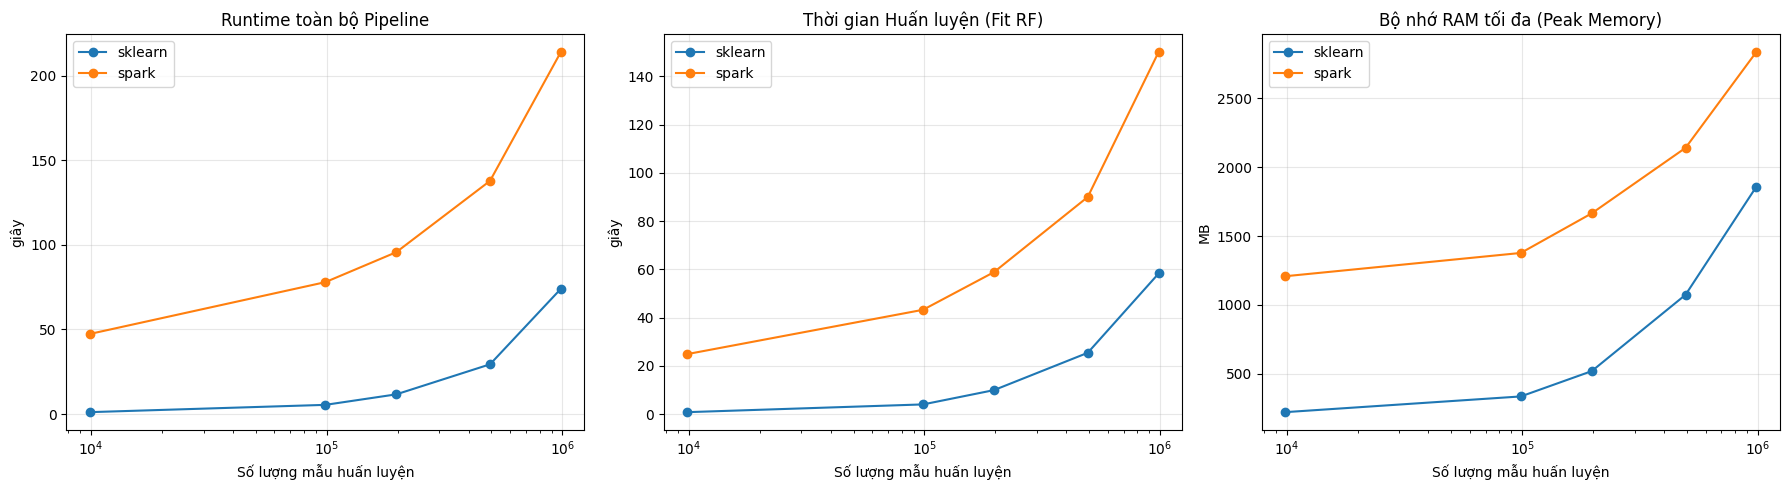

In [ ]:
import matplotlib.pyplot as plt

def md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else str(v) for v in r) + " |")
    return "\n".join(out)

rows = []
for r in results:
    if r["status"] == "OK":
        rows.append({"Scale": f"x{r['scale']}", "Engine": r["engine"], "Rows(train)": r.get("rows_train"),
                     "Load+Replicate(s)": r.get("t_load"), "Clean+FE(s)": r.get("t_clean"),
                     "Encode(s)": r.get("t_encode"), "Fit(s)": r.get("t_fit"), "Predict(s)": r.get("t_pred"),
                     "Total(s)": r.get("t_total"), "PeakMem(MB)": r.get("peak_mem_mb"),
                     "SparkStartup(s)": r.get("t_startup") if r["engine"] == "spark" else None,
                     "Status": r["status"]})
    else:
        rows.append({"Scale": f"x{r['scale']}", "Engine": r["engine"], "Status": r["status"]})

detail = pd.DataFrame(rows).round(2)
detail.to_csv(f"{WORKDIR}/bang_chi_tiet.csv", index=False)
print("===== BẢNG CHI TIẾT TỪNG GIAI ĐOẠN (ĐÃ BAO GỒM X100) =====")
display(detail)

ok = pd.DataFrame([r for r in results if r["status"] == "OK"])
if not ok.empty:
    sk = ok[ok.engine == "sklearn"].set_index("scale"); sp = ok[ok.engine == "spark"].set_index("scale")
    common = sorted(set(sk.index) & set(sp.index))

    if common:
        comp = pd.DataFrame({
            "Scale": [f"x{s}" for s in common],
            "Rows(train)": [int(sk.loc[s, "rows_train"]) for s in common],
            "sklearn Runtime(s)": [sk.loc[s, "t_total"] for s in common],
            "Spark Runtime(s)": [sp.loc[s, "t_total"] for s in common],
            "sklearn/Spark (time)": [sk.loc[s, "t_total"] / sp.loc[s, "t_total"] for s in common],
            "sklearn Mem(MB)": [sk.loc[s, "peak_mem_mb"] for s in common],
            "Spark Mem(MB)": [sp.loc[s, "peak_mem_mb"] for s in common],
            "sklearn/Spark (mem)": [sk.loc[s, "peak_mem_mb"] / sp.loc[s, "peak_mem_mb"] for s in common],
        }).round(2)
        comp.to_csv(f"{WORKDIR}/bang_so_sanh.csv", index=False)
        print("\n===== BẢNG SO SÁNH RUNTIME & MEMORY CỦA QUY MÔ X100 =====")
        display(comp)

        qual = pd.DataFrame({
            "Scale": [f"x{s}" for s in common],
            "sklearn Acc": [sk.loc[s, "accuracy"] for s in common], "Spark Acc": [sp.loc[s, "accuracy"] for s in common],
            "sklearn F1": [sk.loc[s, "f1"] for s in common], "Spark F1": [sp.loc[s, "f1"] for s in common],
            "sklearn AUC": [sk.loc[s, "auc"] for s in common], "Spark AUC": [sp.loc[s, "auc"] for s in common],
        }).round(4)
        print("\n===== BẢNG ĐÁNH GIÁ CHẤT LƯỢNG MÔ HÌNH =====")
        display(qual)

        # Vẽ đồ thị biểu diễn xu hướng
        fig, ax = plt.subplots(1, 3, figsize=(18, 5))
        for eng, col in (("sklearn", "C0"), ("spark", "C1")):
            s = ok[ok.engine == eng]
            if s.empty: continue
            ax[0].plot(s["rows_train"], s["t_total"], "o-", color=col, label=eng)
            ax[1].plot(s["rows_train"], s["t_fit"], "o-", color=col, label=eng)
            ax[2].plot(s["rows_train"], s["peak_mem_mb"], "o-", color=col, label=eng)
        for x, t, yl in zip(ax, ["Runtime toàn bộ Pipeline", "Thời gian Huấn luyện (Fit RF)", "Bộ nhớ RAM tối đa (Peak Memory)"],
                            ["giây", "giây", "MB"]):
            x.set_title(t); x.set_xlabel("Số lượng mẫu huấn luyện"); x.set_ylabel(yl)
            x.set_xscale("log"); x.grid(alpha=.3); x.legend()
        plt.tight_layout(); plt.savefig(f"{WORKDIR}/bieu_do_x100.png", dpi=150); plt.show()

#text5

In [ ]:
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark psutil
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

In [ ]:
import os, time, threading, psutil, numpy as np, pandas as pd

SCALES = [1, 10, 20, 50, 100]          # mức nhân bản (phải xếp tăng dần)

# Lấy thẳng dữ liệu đã xử lý xong ở Mục 2 (không làm lại)
Xtr, ytr = X_train_processed.to_numpy(), y_train.to_numpy()
Xte, yte = X_test_processed.to_numpy(), y_test.to_numpy()
print("Train gốc:", Xtr.shape)
for s in SCALES:
    print(f"  x{s:<4d} -> {Xtr.shape[0] * s:>10,d} dòng train")

def rss_mb():   # RAM của notebook + process con (JVM của Spark)
    p = psutil.Process()
    return round((p.memory_info().rss + sum(c.memory_info().rss for c in p.children(recursive=True))) / 1024**2)

def measure(fn):   # trả về (giây, RAM đỉnh MB, kết quả của fn)
    peak, stop = [0], threading.Event()
    def watch():
        while not stop.is_set():
            try: peak[0] = max(peak[0], rss_mb())
            except psutil.Error: pass
            time.sleep(0.05)
    th = threading.Thread(target=watch); th.start()
    t = time.perf_counter(); out = fn(); sec = time.perf_counter() - t
    stop.set(); th.join()
    return round(sec, 1), max(peak[0], rss_mb()), out

res_sk, res_sp = [], []                # nơi lưu kết quả của 2 môi trường
print("RAM nền của notebook:", rss_mb(), "MB")

Train gốc: (9864, 78)
  x1    ->      9,864 dòng train
  x10   ->     98,640 dòng train
  x20   ->    197,280 dòng train
  x50   ->    493,200 dòng train
  x100  ->    986,400 dòng train
RAM nền của notebook: 302 MB


In [ ]:
from sklearn.ensemble import RandomForestClassifier

def fit_sklearn(scale):
    X, y = np.tile(Xtr, (scale, 1)), np.tile(ytr, scale)             # nhân bản dữ liệu
    return RandomForestClassifier(n_estimators=50, max_depth=10, max_features="sqrt",
                                  n_jobs=-1, random_state=42).fit(X, y)

for s in SCALES:
    print(f"▶ sklearn x{s} ...", flush=True)
    sec, mb, m = measure(lambda: fit_sklearn(s))
    res_sk.append((s, sec, mb, round(m.score(Xte, yte), 4))); del m
    print(f"   {sec}s | {mb} MB")

pd.DataFrame(res_sk, columns=["scale", "sec", "peak_MB", "accuracy"])

▶ sklearn x1 ...
   1.0s | 315 MB
▶ sklearn x10 ...
   10.0s | 419 MB
▶ sklearn x20 ...
   27.3s | 528 MB
▶ sklearn x50 ...
   62.0s | 881 MB
▶ sklearn x100 ...
   83.2s | 1450 MB


,scale,sec,peak_MB,accuracy
0,1,1.0,315,0.8986
1,10,10.0,419,0.8970
2,20,27.3,528,0.8946
3,50,62.0,881,0.8913
4,100,83.2,1450,0.8978


In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.classification import RandomForestClassifier as SRF
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

spark = (SparkSession.builder.master(f"local[{os.cpu_count()}]").config("spark.driver.memory", "4g")
         .config("spark.sql.ansi.enabled", "false").config("spark.ui.enabled", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

cols = [f"f{i}" for i in range(Xtr.shape[1])]
def to_sdf(X, y):
    p = pd.DataFrame(X, columns=cols); p["label"] = y.astype("float64")
    return spark.createDataFrame(p)

base, test_sdf = to_sdf(Xtr, ytr), to_sdf(Xte, yte)
asm = VectorAssembler(inputCols=cols, outputCol="features")

def fit_spark(scale):
    s = base if scale == 1 else base.crossJoin(F.broadcast(spark.range(scale).toDF("r"))).drop("r")  # nhân bản
    s = asm.transform(s).select("features", "label").repartition(os.cpu_count() * 2).cache()
    s.count()                                                        # ép Spark chạy thật (lazy)
    m = SRF(labelCol="label", numTrees=50, maxDepth=10, featureSubsetStrategy="sqrt", seed=42).fit(s)
    s.unpersist()
    return m

print("RAM nền sau khi bật Spark:", rss_mb(), "MB")
for s in SCALES:
    print(f"▶ spark x{s} ...", flush=True)
    sec, mb, m = measure(lambda: fit_spark(s))
    acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy") \
              .evaluate(m.transform(asm.transform(test_sdf)))
    res_sp.append((s, sec, mb, round(acc, 4)))
    print(f"   {sec}s | {mb} MB")

pd.DataFrame(res_sp, columns=["scale", "sec", "peak_MB", "accuracy"])

RAM nền sau khi bật Spark: 797 MB
▶ spark x1 ...
   35.5s | 1667 MB
▶ spark x10 ...
   37.5s | 2372 MB
▶ spark x20 ...
   45.7s | 3281 MB
▶ spark x50 ...
   80.4s | 3314 MB
▶ spark x100 ...
   136.3s | 3354 MB


,scale,sec,peak_MB,accuracy
0,1,35.5,1667,0.8970
1,10,37.5,2372,0.8978
2,20,45.7,3281,0.8994
3,50,80.4,3314,0.8990
4,100,136.3,3354,0.8942


BẢNG SO SÁNH sklearn (đơn máy) vs Spark (phân tán)
Tỉ lệ > 1 nghĩa là Spark nhanh hơn / tốn ít RAM hơn | RAM đã gồm RAM nền của notebook



,Scale,Số dòng train,sklearn Runtime (s),Spark Runtime (s),Runtime sklearn/Spark,Nhanh hơn,sklearn RAM (MB),Spark RAM (MB),RAM sklearn/Spark,sklearn Acc,Spark Acc
0,x1,"9,864",1.0,35.5,0.03,sklearn,315,1667,0.19,0.8986,0.8970
1,x10,"98,640",10.0,37.5,0.27,sklearn,419,2372,0.18,0.8970,0.8978
2,x20,"197,280",27.3,45.7,0.60,sklearn,528,3281,0.16,0.8946,0.8994
3,x50,"493,200",62.0,80.4,0.77,sklearn,881,3314,0.27,0.8913,0.8990
4,x100,"986,400",83.2,136.3,0.61,sklearn,1450,3354,0.43,0.8978,0.8942


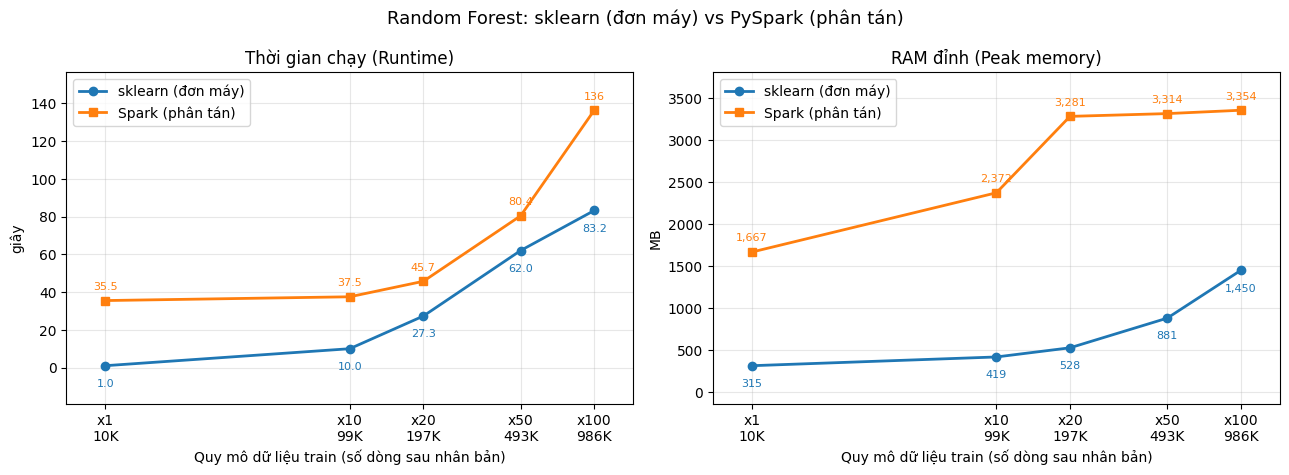

In [51]:
import matplotlib.pyplot as plt

sk = pd.DataFrame(res_sk, columns=["scale", "sk_sec", "sk_MB", "sk_acc"])
sp = pd.DataFrame(res_sp, columns=["scale", "sp_sec", "sp_MB", "sp_acc"])
c = sk.merge(sp, on="scale", how="inner")          # chỉ giữ mức chạy được ở cả 2 môi trường

# ---------- BẢNG ----------
table = pd.DataFrame({
    "Scale": [f"x{s}" for s in c["scale"]],
    "Số dòng train": (c["scale"] * len(Xtr)).map("{:,}".format),
    "sklearn Runtime (s)": c["sk_sec"],
    "Spark Runtime (s)": c["sp_sec"],
    "Runtime sklearn/Spark": (c["sk_sec"] / c["sp_sec"]).round(2),
    "Nhanh hơn": np.where(c["sk_sec"] < c["sp_sec"], "sklearn", "Spark"),
    "sklearn RAM (MB)": c["sk_MB"],
    "Spark RAM (MB)": c["sp_MB"],
    "RAM sklearn/Spark": (c["sk_MB"] / c["sp_MB"]).round(2),
    "sklearn Acc": c["sk_acc"],
    "Spark Acc": c["sp_acc"],
})
print("BẢNG SO SÁNH sklearn (đơn máy) vs Spark (phân tán)")
print("Tỉ lệ > 1 nghĩa là Spark nhanh hơn / tốn ít RAM hơn | RAM đã gồm RAM nền của notebook\n")
table.to_csv("bang_so_sanh.csv", index=False)
display(table)

# ---------- BIỂU ĐỒ ----------
rows = (c["scale"] * len(Xtr)).to_numpy()
labels = [f"x{s}\n{r/1000:,.0f}K" for s, r in zip(c["scale"], rows)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

for a, (k_sk, k_sp, title, unit) in zip(ax, [("sk_sec", "sp_sec", "Thời gian chạy (Runtime)", "giây"),
                                              ("sk_MB", "sp_MB", "RAM đỉnh (Peak memory)", "MB")]):
    a.plot(rows, c[k_sk], "o-", color="tab:blue", lw=2, label="sklearn (đơn máy)")
    a.plot(rows, c[k_sp], "s-", color="tab:orange", lw=2, label="Spark (phân tán)")
    for x, ys, yp in zip(rows, c[k_sk], c[k_sp]):      # nhãn: đường cao ở trên, đường thấp ở dưới
        fmt = lambda v: f"{v:,.0f}" if v >= 100 else f"{v}"
        a.annotate(fmt(ys), (x, ys), textcoords="offset points", xytext=(0, 8 if ys >= yp else -15),
                   ha="center", fontsize=8, color="tab:blue")
        a.annotate(fmt(yp), (x, yp), textcoords="offset points", xytext=(0, 8 if yp > ys else -15),
                   ha="center", fontsize=8, color="tab:orange")
    a.margins(x=0.08, y=0.15)                          # chừa chỗ cho nhãn số
    a.set_xscale("log"); a.minorticks_off()
    a.set_xticks(rows); a.set_xticklabels(labels)
    a.set_title(title, fontsize=12); a.set_ylabel(unit)
    a.set_xlabel("Quy mô dữ liệu train (số dòng sau nhân bản)")
    a.grid(alpha=.3); a.legend()

plt.suptitle("Random Forest: sklearn (đơn máy) vs PySpark (phân tán)", fontsize=13)
plt.tight_layout()
plt.savefig("bieu_do_so_sanh.png", dpi=150)
plt.show()